# ADP 19회 - 분기 시계열 보충

출처: adp_19_summary.pdf pp.4~9: 20년 분기별 Traffic EPS

**복원 연습 자료·예시 풀이이며 공식 정답이 아닙니다.** 원 데이터가 첨부되지 않아 동일 컬럼·분석 주제의 합성 연습 자료를 제공합니다. 수치 정답은 원 시험과 다릅니다.

동봉 data를 사용하며 원 질문·보완 조건·풀이를 분리합니다. 입력 파일은 UTF-8. 저장소 루트 또는 현재 회차 폴더에서 실행할 수 있습니다.

In [1]:
from pathlib import Path
import sys, numpy as np, pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier,GradientBoostingClassifier
from sklearn.svm import SVC
from IPython.display import display
# repository root 또는 회차 폴더에서 탐색; 경로를 하드코딩하지 않음.
ROOT=next(p for p in [Path.cwd()]+list(Path.cwd().parents) if (p/'기출문제/공통/reconstruction.py').exists())
sys.path.insert(0,str(ROOT));sys.path.insert(0,str(ROOT/'기출문제/공통'))
from reconstruction import *
from matplotlib import font_manager
font_path=ROOT/'기출문제/공통/NanumGothic-Regular.ttf'
font_manager.fontManager.addfont(str(font_path))
plt.rcParams['font.family']='NanumGothic';plt.rcParams['axes.unicode_minus']=False
HERE=ROOT/'기출문제'/'19회/보충';DATA=HERE/'data';OUT=HERE/'실행결과';OUT.mkdir(exist_ok=True)
def load(name):return pd.read_csv(DATA/name)
print('데이터 종류: 합성 복원 연습 자료, 원 시험 데이터가 아님')


데이터 종류: 합성 복원 연습 자료, 원 시험 데이터가 아님


## 1. 분기 시계열

자료: traffic_quarterly.csv

80개 관측, 1년=4분기. 기존 월별 연습과 별개이며 정상성·정규성·이분산·자기상관을 구분.

### 2-1

분해와 ADF로 정상성을 점검하고 차분 전후를 비교하시오.

**출처/보완:** 주제는 첨부 자료, 세부 조건·수치는 복원 연습용 보완

**풀이 근거:** ADF 귀무가설은 단위근입니다. 정규성의 검정이 아니며 이분산은 시간별 분산 변화, 자기상관은 잔차 간 상관입니다.

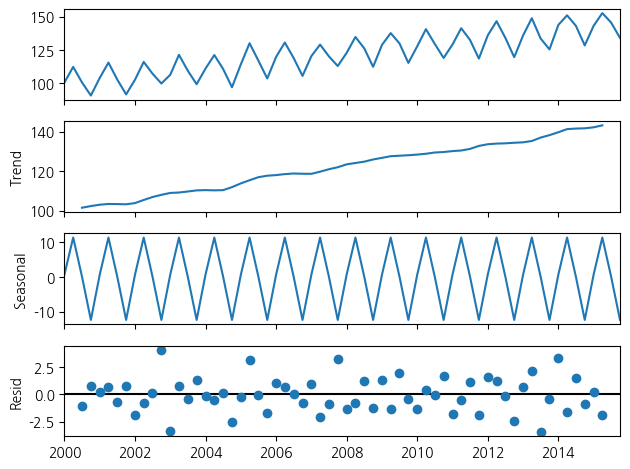

{'ADF_raw': np.float64(0.9632159275003446), 'ADF_seasonal_difference': np.float64(0.31763902536347366)}


In [2]:
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
quarter=load('traffic_quarterly.csv');train_q=quarter.value.iloc[:64]
seasonal_decompose(pd.Series(train_q.to_numpy(),index=pd.to_datetime(quarter.date.iloc[:64])),period=4).plot();plt.show()
print({'ADF_raw':adfuller(train_q)[1],'ADF_seasonal_difference':adfuller(train_q.diff(4).dropna())[1]})

### 2-2

SARIMA 후보를 학습 AIC로 비교해 선택하고, 잔차·잡음과 보류 RMSE/MAE를 보고하시오.

**출처/보완:** 주제는 첨부 자료, 세부 조건·수치는 복원 연습용 보완

**풀이 근거:** 학습 AIC 선정과 test 오차를 구분합니다. 초기 상태 추정의 영향을 고려하고 잔차 정규성만으로 독립성·모형 적합성을 단정하지 않습니다.

       order         AIC  converged
0  (1, 0, 0)  361.601888       True
1  (1, 1, 0)  346.001204       True
2  (0, 1, 1)  330.261675       True
{'order': (0, 1, 1), 'RMSE': 3.0285464223639105, 'MAE': 2.6407259669961807, 'ADF_train_p': 0.9632159275003446}


/root/.local/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency QS-OCT will be used.
  self._init_dates(dates, freq)
/root/.local/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency QS-OCT will be used.
  self._init_dates(dates, freq)
/root/.local/lib/python3.12/site-packages/statsmodels/tsa/statespace/sarimax.py:997: UserWarning: Non-stationary starting seasonal autoregressive Using zeros as starting parameters.
  warn('Non-stationary starting seasonal autoregressive'
/root/.local/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency QS-OCT will be used.
  self._init_dates(dates, freq)
/root/.local/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, 

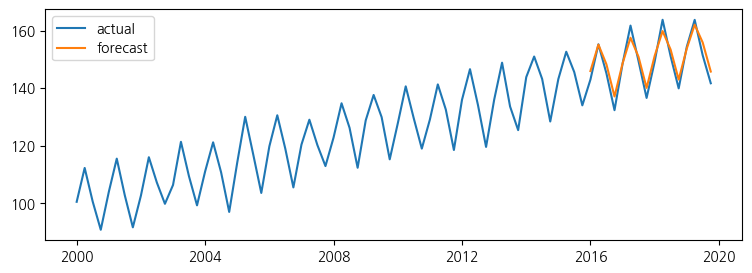

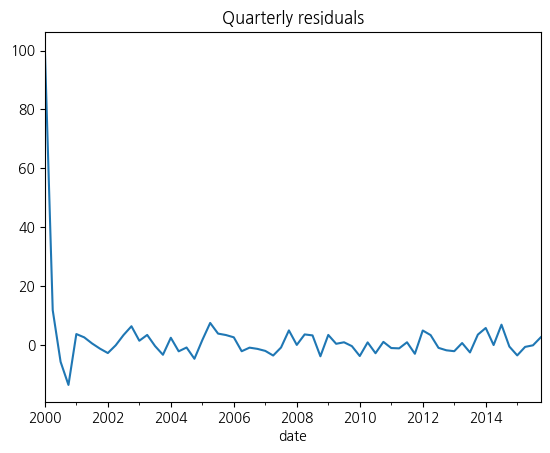

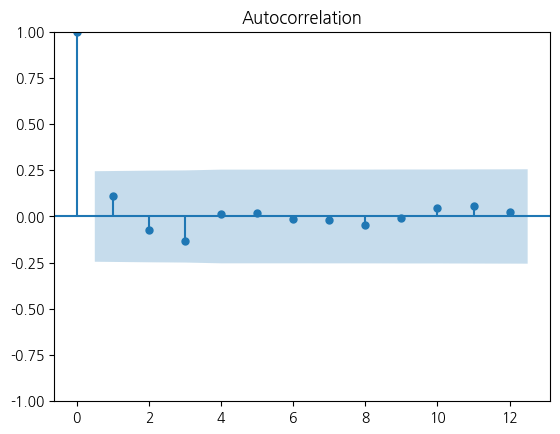

    lb_stat  lb_pvalue
4  2.425512   0.658022
8  2.645172   0.954617
ShapiroResult(statistic=np.float64(0.3278756452628959), pvalue=np.float64(1.4282997421988464e-15))


In [3]:
quarter_model,quarter_metrics=seasonal_forecast(quarter,OUT,period=4)
pd.Series(quarter_model.resid).plot();plt.title('Quarterly residuals');plt.show()
sm.graphics.tsa.plot_acf(quarter_model.resid,lags=12);plt.show()
print(sm.stats.acorr_ljungbox(quarter_model.resid,lags=[4,8],return_df=True));print(stats.shapiro(quarter_model.resid))